# NaijaCost - Part 5: Publication-Grade Visualizations

## Objectives
1. Build comprehensive, high-resolution figures illustrating the findings of the **NaijaCost** project.
2. Export standalone publication assets to `../reports/figures/`:
   - Figure 1: Historical Multi-Staple Price Evolution (2010–2026)
   - Figure 2: Impact of May 2023 Policy Shifts (Subsidy Removal & FX Float)
   - Figure 3: Regional Price Dispersion across Geopolitical Zones
   - Figure 4: Cross-Commodity & Fuel Correlation Heatmap
   - Figure 5: Retail vs Wholesale Markup Distribution
   - Figure 6: Intra-Year Seasonal Fluctuations (Harvest vs Lean Season)


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

fig_dir = Path("../reports/figures")
fig_dir.mkdir(parents=True, exist_ok=True)
clean_file = Path("../data/processed/naijacost_cleaned_food_prices.csv")

df = pd.read_csv(clean_file)
df['date'] = pd.to_datetime(df['date'])
print(f"Loaded {len(df):,} cleaned records.")


Loaded 91,216 cleaned records.


## Visual 1: Historical Multi-Staple Trajectory
Displays the long-term price paths of major Nigerian food staples.


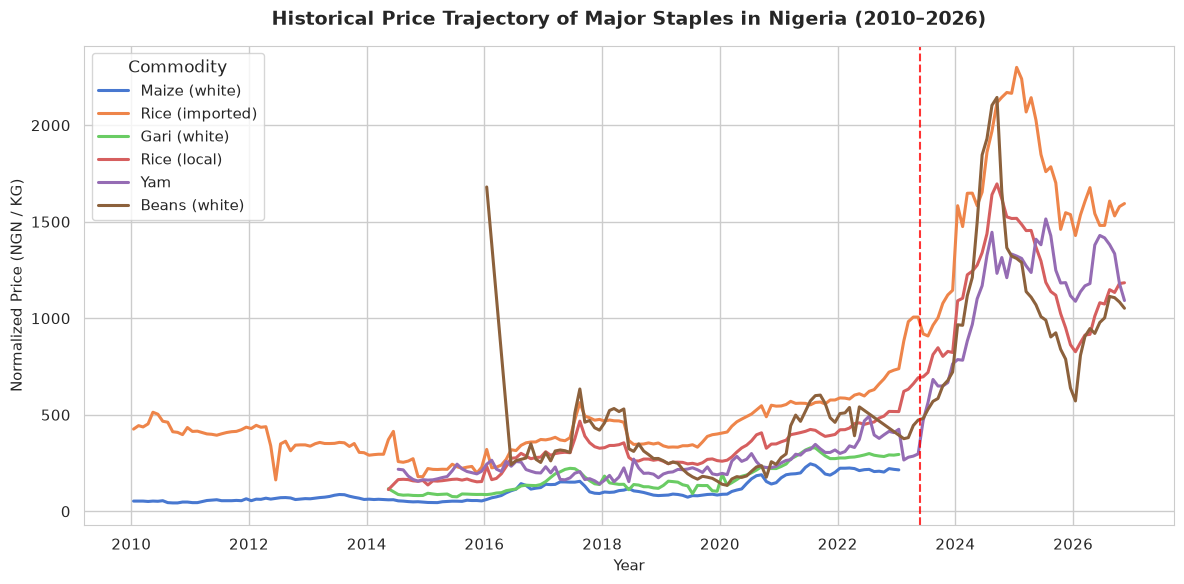

In [2]:
key_staples = ['Rice (imported)', 'Rice (local)', 'Gari (white)', 'Beans (white)', 'Maize (white)', 'Yam']
df_key = df[df['commodity_clean'].isin(key_staples) & (df['base_unit'] == 'KG') & (df['year'] >= 2010)]
monthly_key = df_key.groupby(['date', 'commodity_clean'])['norm_price'].mean().reset_index()

plt.figure(figsize=(12, 6))
sns.lineplot(data=monthly_key, x='date', y='norm_price', hue='commodity_clean', linewidth=2.2)
plt.title("Historical Price Trajectory of Major Staples in Nigeria (2010–2026)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Year", fontsize=11)
plt.ylabel("Normalized Price (NGN / KG)", fontsize=11)
plt.legend(title="Commodity", frameon=True, loc='upper left')
plt.axvline(pd.to_datetime('2023-05-29'), color='red', linestyle='--', alpha=0.8, label='Subsidy Removal (May 2023)')
plt.tight_layout()
plt.savefig(fig_dir / "fig1_staple_price_trends.png", dpi=300)
plt.show()


## Visual 2: Pre vs Post May 2023 Policy Impact
Bar chart illustrating the magnitude of price increases across key food items before vs after the subsidy and FX reforms.


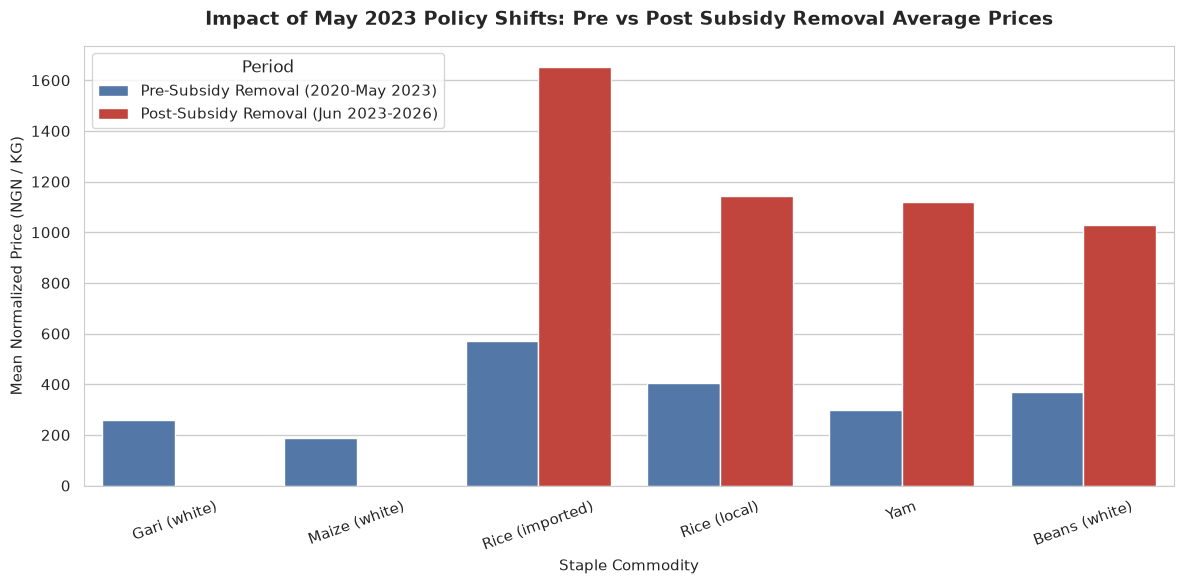

In [3]:
df['period'] = np.where(df['date'] < '2023-06-01', 'Pre-Subsidy Removal (2020-May 2023)', 'Post-Subsidy Removal (Jun 2023-2026)')
df_recent = df[(df['year'] >= 2020) & (df['commodity_clean'].isin(key_staples)) & (df['base_unit'] == 'KG')]

plt.figure(figsize=(12, 6))
sns.barplot(data=df_recent, x='commodity_clean', y='norm_price', hue='period', errorbar=None, palette=['#4575b4', '#d73027'])
plt.title("Impact of May 2023 Policy Shifts: Pre vs Post Subsidy Removal Average Prices", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Staple Commodity", fontsize=11)
plt.ylabel("Mean Normalized Price (NGN / KG)", fontsize=11)
plt.xticks(rotation=20)
plt.legend(title="Period", loc='upper left')
plt.tight_layout()
plt.savefig(fig_dir / "fig2_macro_shocks_subsidy_impact.png", dpi=300)
plt.show()


## Visual 3: Geopolitical Zonal Price Spread
Boxplot revealing regional price differences for staple grains.


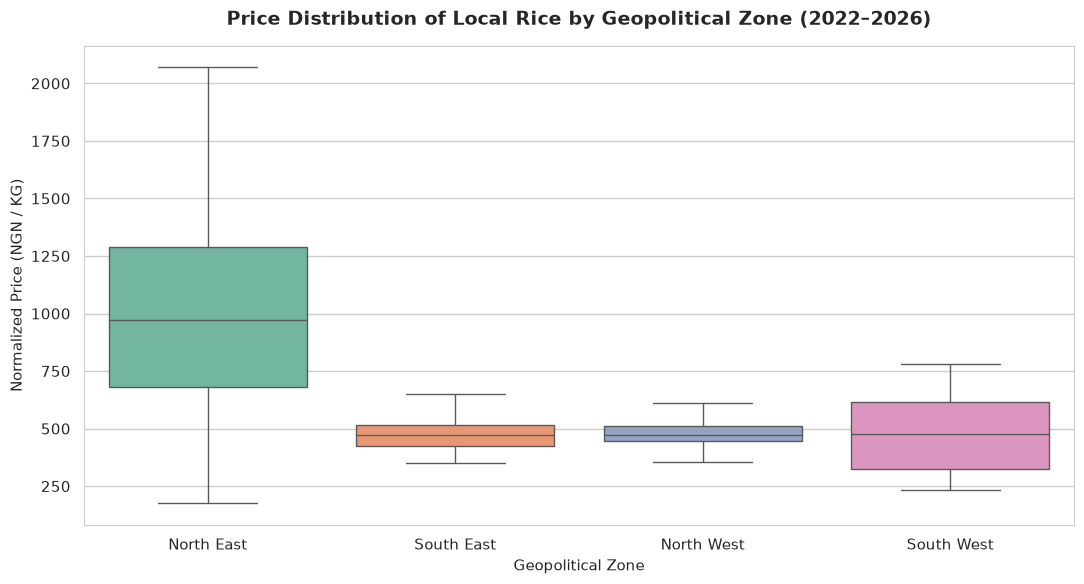

In [4]:
plt.figure(figsize=(11, 6))
df_rice = df[(df['commodity_clean'] == 'Rice (local)') & (df['year'] >= 2022) & (df['base_unit'] == 'KG')]
sns.boxplot(data=df_rice, x='zone', y='norm_price', hue='zone', palette='Set2', showfliers=False, legend=False)
plt.title("Price Distribution of Local Rice by Geopolitical Zone (2022–2026)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Geopolitical Zone", fontsize=11)
plt.ylabel("Normalized Price (NGN / KG)", fontsize=11)
plt.tight_layout()
plt.savefig(fig_dir / "fig3_zone_price_disparities.png", dpi=300)
plt.show()


## Visual 4: Cross-Commodity & Fuel Correlation Heatmap


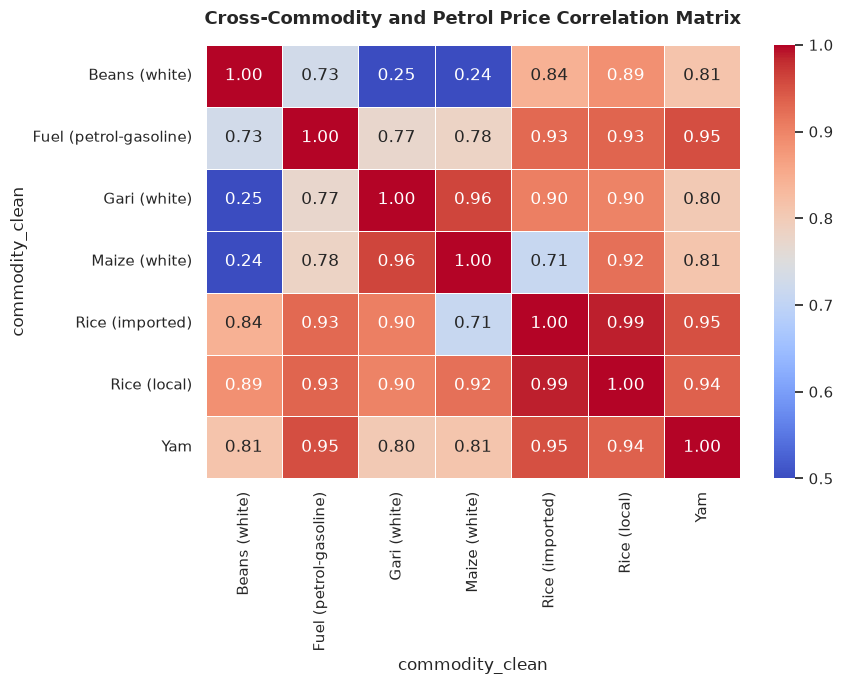

In [5]:
fuel_and_staples = ['Fuel (petrol-gasoline)', 'Rice (imported)', 'Rice (local)', 'Gari (white)', 'Beans (white)', 'Maize (white)', 'Yam']
df_pivot = df[df['commodity_clean'].isin(fuel_and_staples)].groupby(['year_month', 'commodity_clean'])['norm_price'].mean().unstack()
corr_matrix = df_pivot.corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', vmin=0.5, vmax=1.0, linewidths=0.5)
plt.title("Cross-Commodity and Petrol Price Correlation Matrix", fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig(fig_dir / "fig4_commodity_fuel_correlation_heatmap.png", dpi=300)
plt.show()


## Visual 5: Retail Markup Distribution


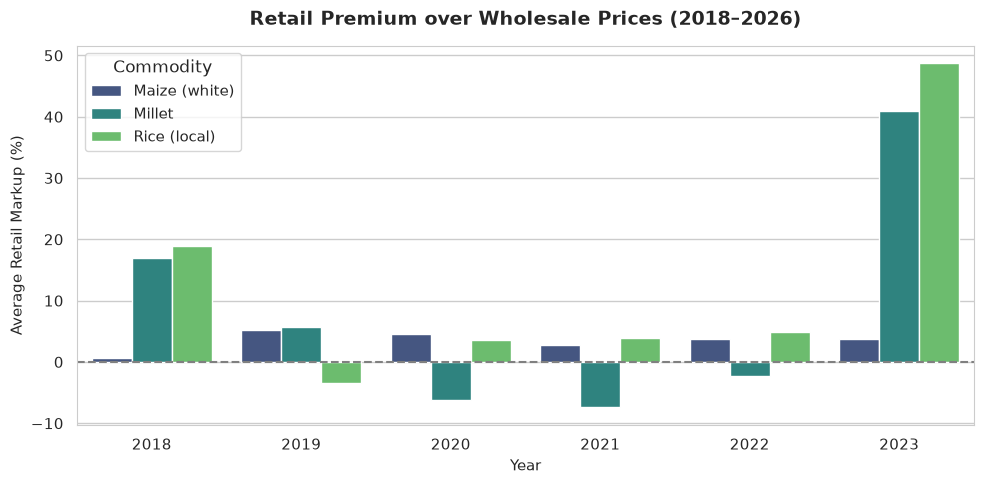

In [6]:
df_spread = df[df['commodity_clean'].isin(['Rice (local)', 'Maize (white)', 'Millet', 'Sorghum']) & (df['base_unit'] == 'KG')]
spread_summary = df_spread.groupby(['year', 'commodity_clean', 'pricetype'])['norm_price'].mean().unstack().dropna()
spread_summary['markup_pct'] = ((spread_summary['Retail'] - spread_summary['Wholesale']) / spread_summary['Wholesale']) * 100
spread_reset = spread_summary.reset_index()

plt.figure(figsize=(10, 5))
sns.barplot(data=spread_reset[spread_reset['year'] >= 2018], x='year', y='markup_pct', hue='commodity_clean', palette='viridis')
plt.title("Retail Premium over Wholesale Prices (2018–2026)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Year", fontsize=11)
plt.ylabel("Average Retail Markup (%)", fontsize=11)
plt.axhline(0, color='gray', linestyle='--')
plt.legend(title="Commodity", loc='upper left')
plt.tight_layout()
plt.savefig(fig_dir / "fig5_retail_vs_wholesale_spread.png", dpi=300)
plt.show()


## Visual 6: Seasonality Patterns Across Calendar Months


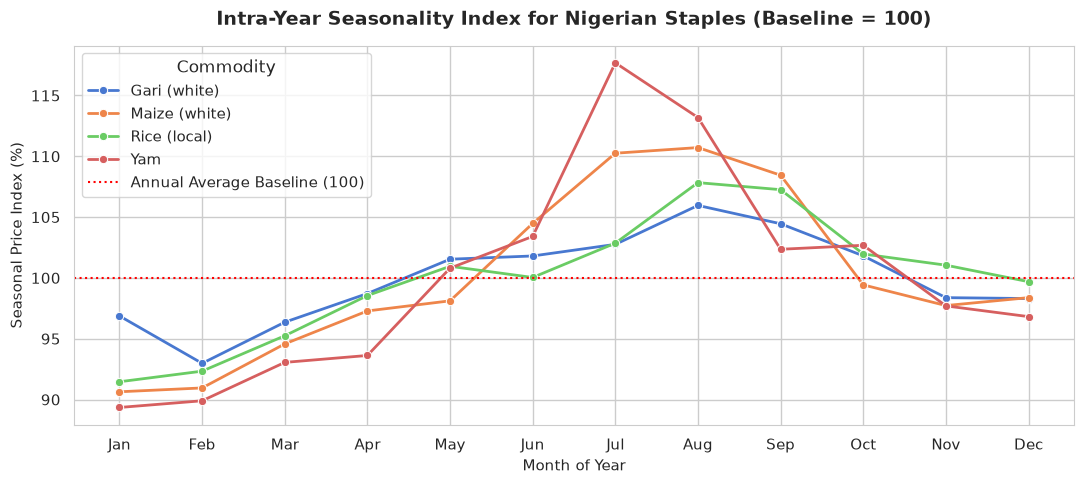

In [7]:
df_season = df[df['commodity_clean'].isin(['Maize (white)', 'Gari (white)', 'Yam', 'Rice (local)']) & (df['base_unit'] == 'KG')].copy()
annual_mean = df_season.groupby(['year', 'commodity_clean'])['norm_price'].transform('mean')
df_season['seasonal_index'] = (df_season['norm_price'] / annual_mean) * 100
monthly_season = df_season.groupby(['month', 'commodity_clean'])['seasonal_index'].mean().reset_index()

plt.figure(figsize=(11, 5))
sns.lineplot(data=monthly_season, x='month', y='seasonal_index', hue='commodity_clean', marker='o', linewidth=2)
plt.title("Intra-Year Seasonality Index for Nigerian Staples (Baseline = 100)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Month of Year", fontsize=11)
plt.ylabel("Seasonal Price Index (%)", fontsize=11)
plt.xticks(range(1, 13), ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
plt.axhline(100, color='red', linestyle=':', label='Annual Average Baseline (100)')
plt.legend(title="Commodity", loc='upper left')
plt.tight_layout()
plt.savefig(fig_dir / "fig6_seasonality_patterns.png", dpi=300)
plt.show()
